# 04 — Decoding intervention on recurrence frontloading

Reproduces the paired $\Delta F$ intervention figure and the absolute before/after trajectory toward the chat/aligned centroid from frozen analysis artifacts in `data/raid_pilot/M_regime_axis_intervention/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT)

ROOT: ..


In [2]:
PROJECT_ROOT = ROOT.parent

D_candidates = [
    DATA / "raid_pilot" / "M_regime_axis_intervention",
    PROJECT_ROOT / "data" / "raid_pilot" / "M_regime_axis_intervention",
    PROJECT_ROOT / "results" / "raid_pilot" / "M_regime_axis_intervention",
]

D = next(
    (
        p for p in D_candidates
        if (p / "regime_axis_intervention_effects.csv").exists()
    ),
    None,
)

assert D is not None, (
    "Could not find M_regime_axis_intervention artifacts. Checked:\n"
    + "\n".join(map(str, D_candidates))
)

print("D:", D)

effects = pd.read_csv(
    D / "regime_axis_intervention_effects.csv"
)

pos = pd.read_csv(
    D / "regime_axis_centroid_positions.csv"
)

cent = pd.read_csv(
    D / "regime_axis_centroids.csv"
)

keep={"sampling_vs_greedy_no_penalty":"Sampling vs greedy","repetition_under_greedy":"Repetition penalty"}
p=effects[effects.contrast.isin(keep)&effects.scope.isin(["base","chat_aligned"])&(effects.metric=="delta_F")].copy(); p["intervention"]=p.contrast.map(keep); p["regime"]=p.scope.map({"base":"Base","chat_aligned":"Chat/aligned"}); p=p[["intervention","regime","n","mean","ci_low","ci_high"]]; p.to_csv(RESULTS/"frontloading_decoding_effects.csv",index=False); display(p)

D: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/M_regime_axis_intervention


,intervention,regime,n,mean,ci_low,ci_high
1,Sampling vs greedy,Base,367,-0.110122,-0.128757,-0.091679
3,Sampling vs greedy,Chat/aligned,462,0.000952,-0.000747,0.002677
6,Repetition penalty,Base,183,-0.104848,-0.128713,-0.082400
8,Repetition penalty,Chat/aligned,141,0.000165,-0.002988,0.003411


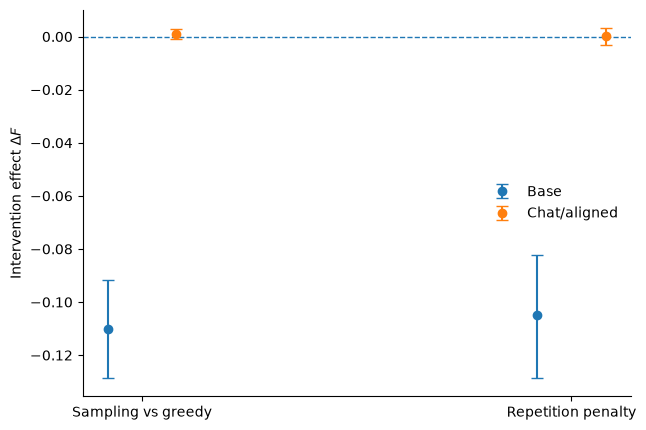

In [3]:
ints=["Sampling vs greedy","Repetition penalty"]; regs=["Base","Chat/aligned"]; x=np.arange(len(ints)); fig,ax=plt.subplots(figsize=(6.6,4.4))
for i,r in enumerate(regs):
    s=p[p.regime==r].set_index("intervention").loc[ints].reset_index(); xpos=x+(-.08 if i==0 else .08); y=s["mean"].to_numpy(); err=np.vstack([y-s.ci_low.to_numpy(),s.ci_high.to_numpy()-y]); ax.errorbar(xpos,y,yerr=err,fmt="o",capsize=4,label=r)
ax.axhline(0,ls="--",lw=1); ax.set_xticks(x); ax.set_xticklabels(ints); ax.set_ylabel(r"Intervention effect $\Delta F$"); ax.legend(frameon=False); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); fig.tight_layout(); fig.savefig(FIGURES/"frontloading_decoding_intervention.pdf",bbox_inches="tight"); fig.savefig(FIGURES/"frontloading_decoding_intervention.png",dpi=300,bbox_inches="tight"); plt.show()

,domain,intervention,mean_F_before,mean_F_after
0,news,Repetition penalty,0.129701,0.003167
1,news,Sampling vs greedy,0.129701,0.008939
2,wiki,Repetition penalty,0.107542,0.009326
3,wiki,Sampling vs greedy,0.107542,0.014963


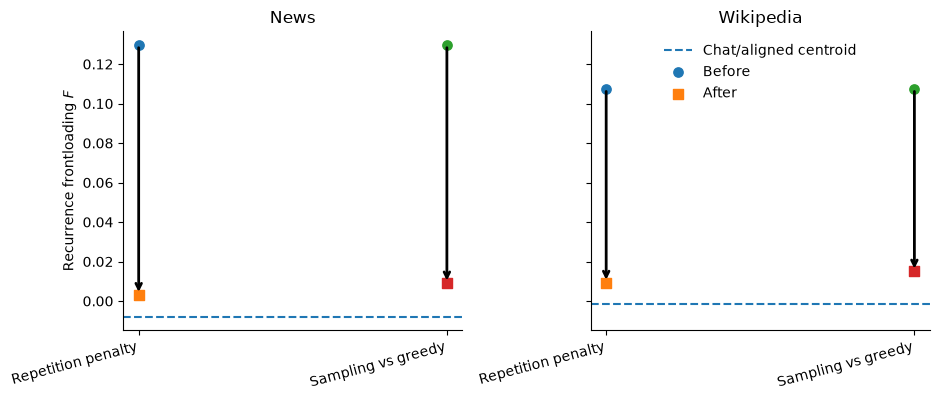

In [4]:
z=pos[pos.contrast.isin(keep)&(pos.regime=="base")].copy(); z["intervention"]=z.contrast.map(keep); tr=z.groupby(["domain","intervention"])[["mean_F_before","mean_F_after"]].mean().reset_index(); tr.to_csv(RESULTS/"frontloading_intervention_trajectory.csv",index=False); display(tr)
fig,axes=plt.subplots(1,2,figsize=(9.5,4.1),sharey=True)
for ax,domain in zip(axes,["news","wiki"]):
    s=tr[tr.domain==domain].copy(); chat=cent.loc[cent.domain==domain,"mu_chat"].iloc[0]; ax.axhline(chat,ls="--",lw=1.5,label="Chat/aligned centroid"); x=np.arange(len(s))
    for i,(_,r) in enumerate(s.iterrows()):
        ax.annotate("",xy=(i,r.mean_F_after),xytext=(i,r.mean_F_before),arrowprops=dict(arrowstyle="->",linewidth=2)); ax.scatter(i,r.mean_F_before,marker="o",s=45,label="Before" if i==0 else None); ax.scatter(i,r.mean_F_after,marker="s",s=45,label="After" if i==0 else None)
    ax.set_xticks(x); ax.set_xticklabels(s.intervention,rotation=15,ha="right"); ax.set_title("News" if domain=="news" else "Wikipedia"); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
axes[0].set_ylabel(r"Recurrence frontloading $F$"); axes[1].legend(frameon=False); fig.tight_layout(); fig.savefig(FIGURES/"frontloading_intervention_trajectory.pdf",bbox_inches="tight"); fig.savefig(FIGURES/"frontloading_intervention_trajectory.png",dpi=300,bbox_inches="tight"); plt.show()